# 08O: Object-bank evaluation

Evaluate the sealed predictions on the declared development cohort. Keep every expected scene, compare the predefined methods and routes, and save scientific results before reporting or tracking.

## Saved-output evidence copy

This notebook records the completed run for repository review. Its code and markdown match the clean runnable notebook. Private scene visuals and identifier-bearing output were removed. Safe aggregate tables and charts were retained.

Run stage: `08O local development`  
Clean notebook SHA-256: `e569bdaa5ebc56faee8af07a40893e46c7749d17653296c7a23f0123536af664`  
Downloaded saved-output SHA-256: `978bf9e309ea085891518cc1f184f63e3f7541939d1edb9b6edb9add5b3498ef`


## Frozen comparison

LocateAnything-3B, SAM 2.1 and DINOv2-small remain fixed. The existing 100-scene development screen supplies 19 predefined schedules: five each with 1, 2 and 3 views, and four with 5 views. Three and five views are the application settings; one and two views are diagnostics. Every prediction uses only its selected views. This bounded stage does not claim results for 10 or 20 views.

| Route | Object regions | Cross-view identity | Interpretation |
| --- | --- | --- | --- |
| `supplied_reference` | Supplied masks | Supplied neutral correspondence | Scoring diagnostic |
| `automatic_reference` | Saved LocateAnything and SAM outputs | Supplied neutral correspondence | Region diagnostic; assisted identity |
| `automatic_predicted` | Saved LocateAnything and SAM outputs | Existing automatic association | Automatic application route |

Anomaly labels are available only to the evaluator, after predictions are sealed. All valid candidates remain represented. An unmatched observation stays visible in the output; its object-bank score is unavailable because exclusion of another view of itself cannot be guaranteed. Missing observations are never replaced with normal scores. One object cannot contain two detections from the same view.

**Patch comparison.** For each target foreground patch, compute the minimum cosine distance to a peer object's patches across that peer's selected views. Each peer contributes one distance. Take the lower median across peers, then average the largest `max(1, floor(0.02 × target patch count))` patch distances. Exclude the target's complete identity from all peer banks. At least two usable peers are required.

Compare this object bank with regenerated within-view scoring and cached forward scoring. `view_mean_control` first averages nearest-patch distances across each peer's usable views. It diagnoses the extra matching opportunities in a larger bank; it is not a guarantee of invariance to bank size.

**One physical-object ranking.** Convert available observation scores into average within-view percentile ranks when at least three candidates are scored. Compare the mean of all valid ranks with the mean of the strongest two (or the single available rank). Retain the existing winner-consensus method as a comparison. The scorer's raw-score means are diagnostics; final rankings use the declared rank normalization.

**Decision gate.** Choose between the two bank fusions using the supplied-reference primary three-view development result: the paired asset-bootstrap 95% lower bound for top-1 improvement must be positive, AP and Recall@2 must not regress, and the mean top-1 improvement across the five three-view schedules must be positive. Prefer mean fusion on a tie. If the gate fails, stop the scoring extension and retain the stronger existing method. Results remain development evidence; 60% is a goal, not a promised outcome.

Report tie-aware top-1, Recall@2, reciprocal rank and average precision, with asset-grouped uncertainty and explicit candidate, association and ranking losses. A scene contributes one result per setting; its views are not independent successes.

## Runtime and configuration

In [1]:
from pathlib import Path
import json
import os
import sys

def is_source(path):
    return (path / "scripts/run_object_bank.py").is_file() and (path / "src/vpi_object_bank").is_dir()

def locate_source():
    explicit = os.environ.get("VPI_OBJECT_BANK_ROOT")
    if explicit:
        root = Path(explicit).expanduser().resolve()
        if not is_source(root):
            raise RuntimeError("The configured source root is incomplete")
        return root
    for root in (Path.cwd(), *list(Path.cwd().parents)[:6]):
        if is_source(root):
            return root
    candidates = set()
    input_root = Path("/kaggle/input")
    if input_root.is_dir():
        for pattern in ("*", "datasets/*/*", "datasets/*/*/versions/*", "notebooks/*/*"):
            for mount in input_root.glob(pattern):
                if not mount.is_dir():
                    continue
                if is_source(mount):
                    candidates.add(mount.resolve())
                children = list(mount.iterdir())
                if len(children) <= 200:
                    candidates.update(child.resolve() for child in children if child.is_dir() and is_source(child))
    if len(candidates) != 1:
        raise RuntimeError("Expected exactly one complete object-bank source resource")
    return candidates.pop()

SOURCE_ROOT = locate_source()
CONFIG_PATH = Path(os.environ.get("VPI_OBJECT_BANK_CONFIG", SOURCE_ROOT / ".local/config.json")).expanduser().resolve()
if not CONFIG_PATH.is_file():
    raise RuntimeError("Provide the verified local or Kaggle configuration JSON")
configuration = json.loads(CONFIG_PATH.read_text())
sys.path.insert(0, str(SOURCE_ROOT / "scripts"))
sys.path.insert(0, str(SOURCE_ROOT / "src"))
from scoring_comparison_runtime import run_bounded
os.environ["PYTHONPATH"] = str(SOURCE_ROOT / "src")
os.environ["PYTHONDONTWRITEBYTECODE"] = "1"
LOG_ROOT = SOURCE_ROOT / ".local/logs"
if str(SOURCE_ROOT).startswith("/kaggle/input/"):
    LOG_ROOT = Path("/kaggle/working/object-bank-logs")
LOG_ROOT.mkdir(parents=True, exist_ok=True)

def run_stage(stage):
    run_bounded(
        [sys.executable, str(SOURCE_ROOT / "scripts/run_object_bank.py"), stage, "--config", str(CONFIG_PATH)],
        LOG_ROOT / (stage + ".log"), idle_seconds=900, total_seconds=18000,
    )
print({"event": "notebook_ready", "python": sys.version.split()[0]})

{'event': 'notebook_ready', 'python': '3.12.14'}


## Evaluate frozen predictions

In [2]:
run_stage("evaluate")

{"result": {"aggregation": "one row per scene per method; schedules averaged within scene before asset bootstrap", "asset_group_count": 27, "bootstrap": {"samples": 2000, "seed": 32040, "unit": "asset_group"}, "elapsed_seconds": 8.1129767909988, "historical_baseline_checks": [{"expected": 0.37666666666666665, "method": "winner_cluster_consensus", "metric": "top1_tie_expected", "observed": 0.37666666666666665, "passed": true, "route": "automatic_predicted", "view_set_id": "three-primary"}, {"expected": 0.5116666666666667, "method": "cached_forward_mean", "metric": "top1_tie_expected", "observed": 0.5116666666666666, "passed": true, "route": "supplied_reference", "view_set_id": "three-primary"}, {"expected": 0.61, "method": "cached_forward_mean", "metric": "top1_tie_expected", "observed": 0.61, "passed": true, "route": "supplied_reference", "view_set_id": "five-primary"}], "identity_undefined": "no cross-view pairs yields undefined precision/recall; defined_scene_count is explicit", "map

## Report evidence and limitations

In [3]:
run_stage("report")

{"result": {"aggregate_figures": ["view_count_accuracy.png", "paired_improvement.png"], "gallery_count": 18, "heatmap_scope": "coarse patch evidence, not validated defect masks", "source": "sealed development predictions", "status": "completed"}, "stage": "report"}


## Verify scientific results and reports

In [4]:
run_stage("verify")

{"result": {"evaluation_root": {"verified_files": 211}, "feature_root": {"verified_files": 12002}, "prediction_root": {"verified_files": 301}, "prepared_root": {"verified_files": 101}, "report_root": {"verified_files": 23}}, "stage": "verify"}


## Aggregate results and method decision

In [5]:
from IPython.display import display
import pandas as pd

aggregate_root = Path(configuration["evaluation_root"]) / "shareable"
metrics = pd.read_csv(aggregate_root / "metric_summary.csv")
schedules = pd.read_csv(aggregate_root / "view_schedule_summary.csv")
display(metrics)
schedule_column = next((name for name in ("view_set_id", "view_schedule", "schedule") if name in schedules), None)
primary = schedules[schedules[schedule_column].astype(str).str.endswith("primary")] if schedule_column else schedules
# Display the long form as well as a compact primary-schedule pivot.
display(primary)
value_column = next((name for name in ("estimate", "value", "mean", "point_estimate") if name in primary), None)
if "metric" in primary and value_column:
    index_columns = [name for name in ("route", "method", "view_count", schedule_column) if name and name in primary]
    display(primary.pivot_table(index=index_columns, columns="metric", values=value_column, aggfunc="first"))
else:
    value_columns = [name for name in ("top1_tie_expected", "recall_at_2_tie_expected", "ap_tie_expected", "reciprocal_rank_tie_expected") if name in primary]
    index_columns = [name for name in ("route", "method", "view_count", schedule_column) if name and name in primary]
    if value_columns and index_columns:
        display(primary.set_index(index_columns)[value_columns])
display(pd.read_csv(aggregate_root / "paired_asset_intervals.csv"))
display(pd.read_csv(aggregate_root / "failure_summary.csv"))
decision = json.loads((aggregate_root / "decision.json").read_text())
display(decision)

,route,method,view_count,metric,mean,ci_low,ci_high,scene_count,asset_group_count
0,automatic_predicted,cached_forward_mean,1,top1_tie_expected,0.481000,0.420384,0.546163,100,27
1,automatic_predicted,cached_forward_mean,1,recall_at_2_tie_expected,0.654500,0.606558,0.700971,100,27
2,automatic_predicted,cached_forward_mean,1,ap_tie_expected,0.659652,0.621668,0.699341,100,27
3,automatic_predicted,cached_forward_mean,1,reciprocal_rank_tie_expected,0.672833,0.632820,0.714339,100,27
4,automatic_predicted,cached_forward_mean,2,top1_tie_expected,0.210000,0.157092,0.278424,100,27
...,...,...,...,...,...,...,...,...,...
395,supplied_reference,within_view_top2,3,reciprocal_rank_tie_expected,0.738131,0.688126,0.789777,100,27
396,supplied_reference,within_view_top2,5,top1_tie_expected,0.538833,0.460839,0.613961,100,27
397,supplied_reference,within_view_top2,5,recall_at_2_tie_expected,0.755792,0.697675,0.810099,100,27
398,supplied_reference,within_view_top2,5,ap_tie_expected,0.726899,0.680200,0.770843,100,27


,route,method,view_count,view_set_id,metric,mean,ci_low,ci_high,scene_count,asset_group_count
0,automatic_predicted,cached_forward_mean,1,one-primary,top1_tie_expected,0.560000,0.455446,0.666667,100,27
1,automatic_predicted,cached_forward_mean,1,one-primary,recall_at_2_tie_expected,0.710000,0.632653,0.784213,100,27
2,automatic_predicted,cached_forward_mean,1,one-primary,ap_tie_expected,0.709500,0.650500,0.770590,100,27
3,automatic_predicted,cached_forward_mean,1,one-primary,reciprocal_rank_tie_expected,0.728000,0.666130,0.791001,100,27
20,automatic_predicted,cached_forward_mean,2,two-primary,top1_tie_expected,0.246667,0.163332,0.338055,100,27
...,...,...,...,...,...,...,...,...,...,...
1867,supplied_reference,within_view_top2,3,three-primary,reciprocal_rank_tie_expected,0.714944,0.654891,0.778149,100,27
1884,supplied_reference,within_view_top2,5,five-primary,top1_tie_expected,0.576667,0.476898,0.678113,100,27
1885,supplied_reference,within_view_top2,5,five-primary,recall_at_2_tie_expected,0.791667,0.718934,0.857744,100,27
1886,supplied_reference,within_view_top2,5,five-primary,ap_tie_expected,0.752556,0.694930,0.808834,100,27


metric                                                            ap_tie_expected  \
route               method              view_count view_set_id
automatic_predicted cached_forward_mean 1          one-primary           0.709500
                                        2          two-primary           0.326375
                                        3          three-primary         0.321465
                                        5          five-primary          0.266839
                    cached_forward_top2 1          one-primary           0.709500
...                                                                           ...
supplied_reference  within_view_mean    5          five-primary          0.769333
                    within_view_top2    1          one-primary           0.711583
                                        2          two-primary           0.681622
                                        3          three-primary         0.710833
                                        5          five-primary          0.752556

metric                                                            recall_at_2_tie_expected  \
route               method              view_count view_set_id
automatic_predicted cached_forward_mean 1          one-primary                    0.710000
                                        2          two-primary                    0.323333
                                        3          three-primary                  0.334167
                                        5          five-primary                   0.292500
                    cached_forward_top2 1          one-primary                    0.710000
...                                                                                    ...
supplied_reference  within_view_mean    5          five-primary                   0.817500
                    within_view_top2    1          one-primary                    0.715000
                                        2          two-primary                    0.662333
                                        3          three-primary                  0.728333
                                        5          five-primary                   0.791667

metric                                                            reciprocal_rank_tie_expected  \
route               method              view_count view_set_id
automatic_predicted cached_forward_mean 1          one-primary                        0.728000
                                        2          two-primary                        0.350639
                                        3          three-primary                      0.346851
                                        5          five-primary                       0.292583
                    cached_forward_top2 1          one-primary                        0.728000
...                                                                                        ...
supplied_reference  within_view_mean    5          five-primary                       0.779500
                    within_view_top2    1          one-primary                        0.725667
                                        2          two-primary                        0.691678
                                        3          three-primary                      0.714944
                                        5          five-primary                       0.760861

metric                                                            top1_tie_expected
route               method              view_count view_set_id
automatic_predicted cached_forward_mean 1          one-primary             0.560000
                                        2          two-primary             0.246667
                                        3          three-primary           0.205000
                                        5          five-primary            0.165000
                    cached_forward_top2 1          one-primary             0.560000
...             

,route,method,view_count,view_set_id,baseline,metric,delta,ci_low,ci_high,scene_count,asset_group_count
0,automatic_predicted,cached_forward_mean,1,one-primary,within_view_mean,top1_tie_expected,0.000000,0.000000,0.000000,100,27
1,automatic_predicted,cached_forward_mean,1,one-primary,within_view_mean,recall_at_2_tie_expected,-0.005000,-0.015306,0.000000,100,27
2,automatic_predicted,cached_forward_mean,1,one-primary,within_view_mean,ap_tie_expected,-0.001667,-0.005102,0.000000,100,27
3,automatic_predicted,cached_forward_mean,1,one-primary,within_view_mean,reciprocal_rank_tie_expected,0.000000,0.000000,0.000000,100,27
4,automatic_predicted,cached_forward_mean,1,one-rotated-04,within_view_mean,top1_tie_expected,-0.010000,-0.030612,0.000000,100,27
...,...,...,...,...,...,...,...,...,...,...,...
2019,supplied_reference,within_view_top2,3,all-schedules,within_view_mean,reciprocal_rank_tie_expected,-0.003886,-0.017989,0.008139,100,27
2020,supplied_reference,within_view_top2,5,all-schedules,within_view_mean,top1_tie_expected,-0.062417,-0.099850,-0.024336,100,27
2021,supplied_reference,within_view_top2,5,all-schedules,within_view_mean,recall_at_2_tie_expected,-0.012542,-0.046043,0.019584,100,27
2022,supplied_reference,within_view_top2,5,all-schedules,within_view_mean,ap_tie_expected,-0.027879,-0.049066,-0.007534,100,27


,route,method,view_count,view_set_id,metric,mean,scene_count,defined_scene_count,asset_group_count
0,automatic_predicted,cached_forward_mean,1,all-schedules,candidate_coverage,0.960,100,100,27
1,automatic_predicted,cached_forward_mean,1,all-schedules,candidate_anomaly_recall,0.957,100,100,27
2,automatic_predicted,cached_forward_mean,1,all-schedules,detection_loss,0.040,100,100,27
3,automatic_predicted,cached_forward_mean,1,all-schedules,pruning_loss,0.000,100,100,27
4,automatic_predicted,cached_forward_mean,1,all-schedules,association_loss,0.000,100,100,27
...,...,...,...,...,...,...,...,...,...
1395,supplied_reference,within_view_top2,5,all-schedules,retained_candidate_count,19.250,100,100,27
1396,supplied_reference,within_view_top2,5,all-schedules,unknown_candidate_count,0.000,100,100,27
1397,supplied_reference,within_view_top2,5,all-schedules,unscored_object_count,0.000,100,100,27
1398,supplied_reference,within_view_top2,5,all-schedules,scored_object_count,3.850,100,100,27


{'baseline_method': 'within_view_mean',
 'decision': 'continue_bounded_mapping',
 'diagnostic_controls_eligible': False,
 'eligible_candidates': [{'method': 'object_bank_mean',
   'passed': True,
   'primary_ap_delta': 0.041527777777777775,
   'primary_recall_at_2_delta': 0.003333333333333335,
   'primary_top1_ci_low': 0.006666666666666671,
   'primary_top1_delta': 0.095,
   'three_view_schedule_mean_top1_delta': 0.09486666666666667},
  {'method': 'object_bank_top2',
   'passed': True,
   'primary_ap_delta': 0.058576388888888886,
   'primary_recall_at_2_delta': 0.006666666666666667,
   'primary_top1_ci_low': 0.04713273511817202,
   'primary_top1_delta': 0.13083333333333333,
   'three_view_schedule_mean_top1_delta': 0.10169999999999998}],
 'interpretation': 'development selection only; supplied correspondence; no independent confirmation',
 'mapping_allowed': True,
 'schema': 'vpi-object-bank/v1',
 'selected_method': 'object_bank_top2',
 'selection_basis': {'candidate_fusions': ['mean',

## Aggregate figures

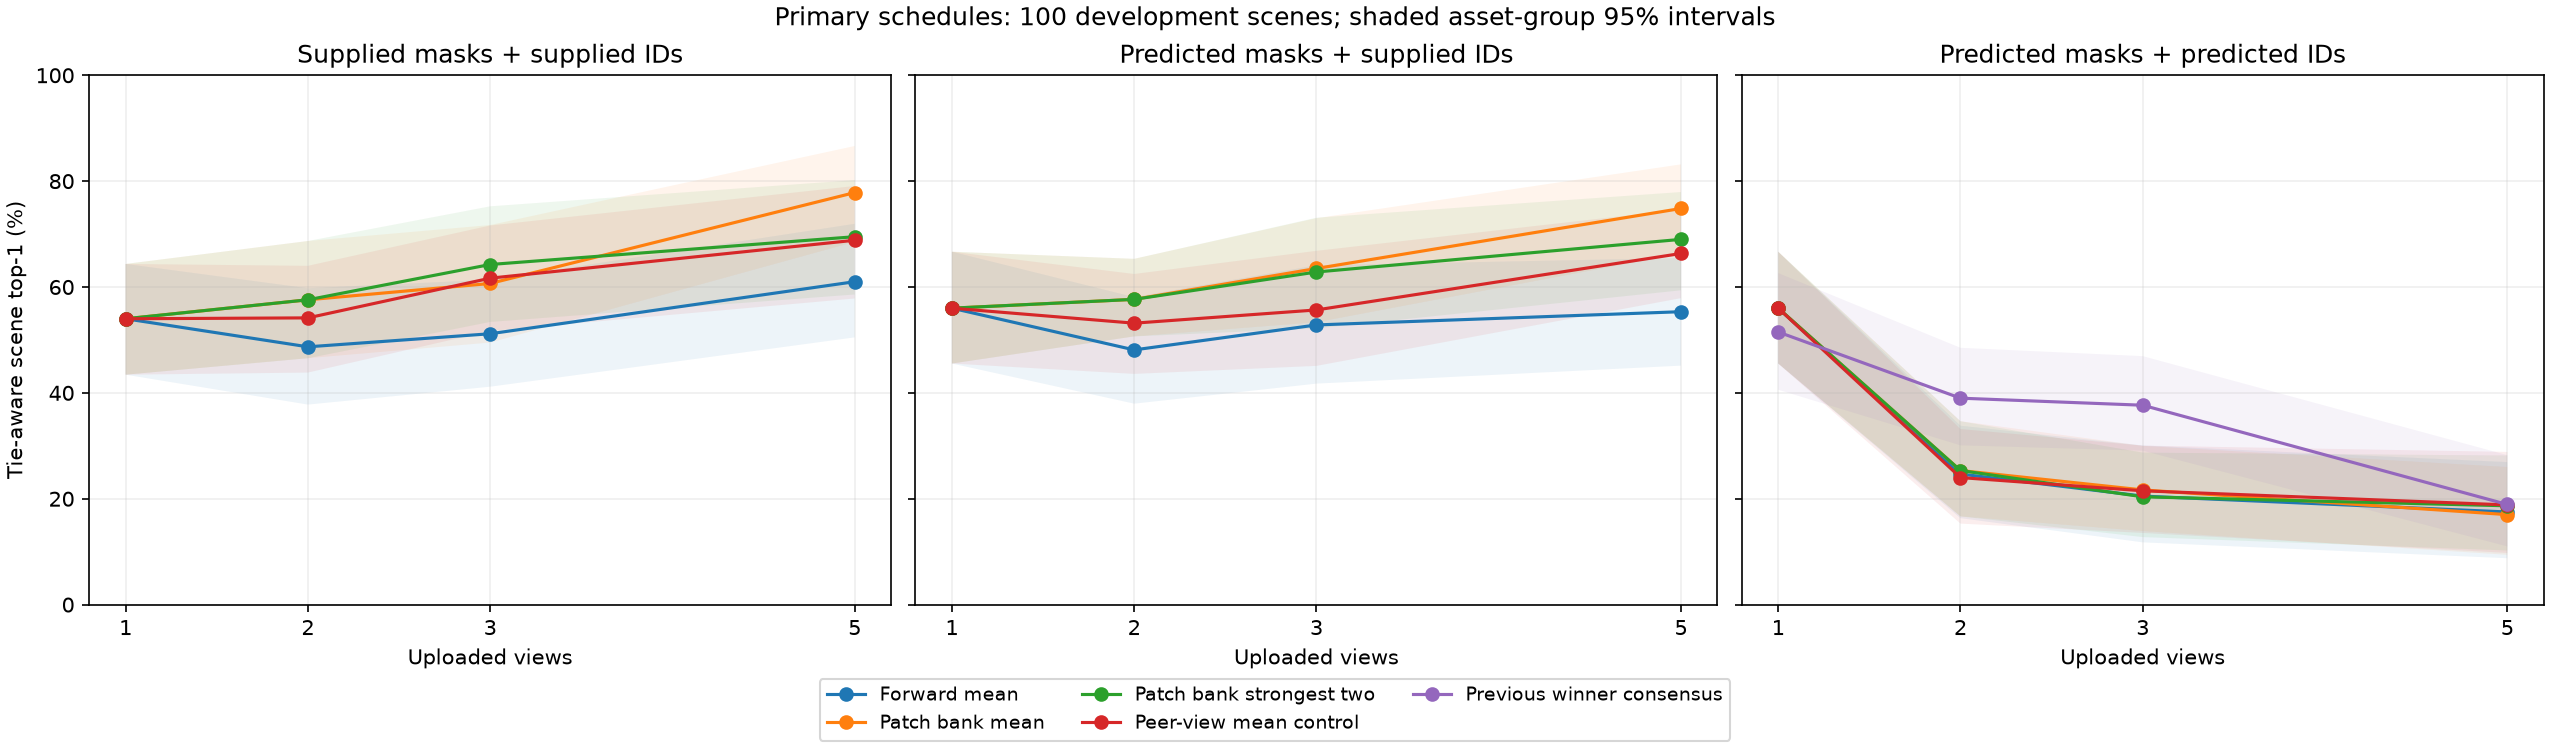

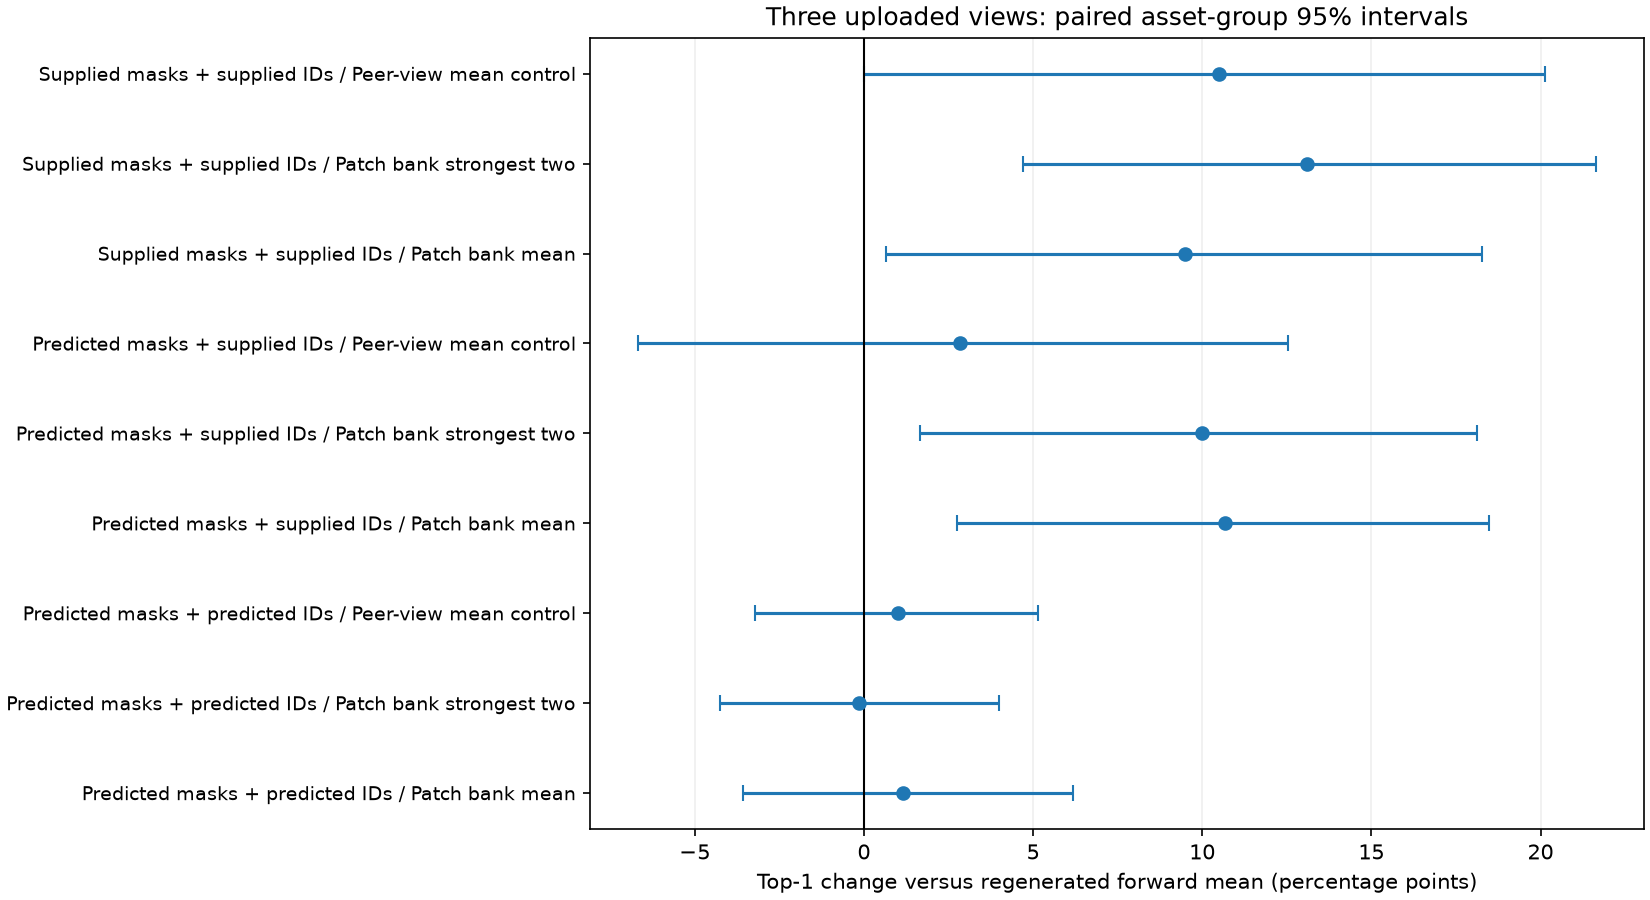

In [6]:
from IPython.display import Image, display

figure_root = Path(configuration["report_root"]) / "shareable/figures"
for name in ("view_count_accuracy.png", "paired_improvement.png", "failure_waterfall.png"):
    figure = figure_root / name
    if figure.is_file():
        display(Image(filename=str(figure)))

## Private multi-view gallery

The fixed first scene is an outcome-independent example. Any largest-gain or largest-loss illustrations in the local report are post-hoc explanations, not a demonstration accuracy estimate.

In [7]:
# Private review evidence: the publishing helper removes these image outputs.
from IPython.display import Image, display

private_root = Path(configuration["report_root"]) / "private"
gallery = json.loads((private_root / "gallery_manifest.json").read_text())
if gallery:
    first_scene = gallery[0]["scene"]
    examples = [item for item in gallery if item["scene"] == first_scene and item["method"] == "object_bank_mean"]
    for example in examples:
        print({"route": example["route"], "selection_reason": example["selection_reason"],
               "top_tie_count": example["top_tie_count"], "unlocated_views": example["unlocated_views"]})
        display(Image(filename=str(private_root / example["file"])))
print("Gallery heatmaps are coarse patch evidence, not validated defect masks.")

{'route': 'supplied_reference', 'selection_reason': 'fixed first development scene', 'top_tie_count': 1, 'unlocated_views': []}


<IPython.core.display.Image object>

{'route': 'automatic_reference', 'selection_reason': 'fixed first development scene', 'top_tie_count': 1, 'unlocated_views': []}


<IPython.core.display.Image object>

{'route': 'automatic_predicted', 'selection_reason': 'fixed first development scene', 'top_tie_count': 1, 'unlocated_views': []}


<IPython.core.display.Image object>

Gallery heatmaps are coarse patch evidence, not validated defect masks.


## Selected-method multi-view evidence

These private examples use the method chosen by the predefined gate. They illustrate its decision and limitations; they are not a new evaluation subset.

In [8]:
# Private selected-method evidence is excluded from repository publication.
sys.path.insert(0, str(SOURCE_ROOT / "src"))
from vpi_object_bank.selected_demo import build_selected_demo
selected_receipt = build_selected_demo(configuration, SOURCE_ROOT)
print(selected_receipt)
selected_root = Path(configuration.get("selected_demo_root", Path(configuration["report_root"]).parent / "selected-demo"))
selected_images = sorted((selected_root / "private").glob("*-automatic_reference-*.png"))
if selected_images:
    from IPython.display import Image, display
    display(Image(filename=str(selected_images[0])))

{'status': 'completed', 'method': 'object_bank_top2', 'gallery_count': 9, 'scope': 'private development examples; separate from evaluation denominator'}


<IPython.core.display.Image object>

## Publish aggregate evidence

Tracking runs in a separate process after verified scientific results. A tracking failure leaves a retryable receipt and does not repeat computation. Private examples remain in the local review artifacts.

In [9]:
import subprocess
# Display only the publisher's compact status, never third-party output.
try:
    publication = subprocess.run(
        [sys.executable, str(SOURCE_ROOT / "scripts/publish_clearml.py"),
         "--config", str(CONFIG_PATH), "--bounded", "--timeout", "180"],
        capture_output=True, text=True, timeout=195,
    )
    tracking = json.loads(publication.stdout.strip().splitlines()[-1])
    print({"event": "tracking_finished", "status": tracking.get("status", "pending"),
           "task_id": tracking.get("task_id")})
except (ValueError, IndexError, OSError, subprocess.TimeoutExpired):
    print({"event": "tracking_finished", "status": "pending"})

{'event': 'tracking_finished', 'status': 'completed', 'task_id': 'acd73b155c49417bbb00e6d17b324a6e'}
